In [10]:

import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

df = pd.read_csv("../data/raw/kredit_sumatera.csv")
df["rasio_angsuran"] = df.angsuran_bulanan / df.penghasilan_bulanan
num = ["usia", "tanggungan", "lama_usaha_tahun", "penghasilan_bulanan",
       "ragam_penghasilan", "plafon_diajukan", "tenor_bulan", "bunga_tahunan",
       "rasio_angsuran", "rata_saldo_90h", "jumlah_tunggakan_12b"]
X = df[num].join(pd.get_dummies(df[["segmen", "wilayah", "kanal"]]))
y = df.gagal_bayar

latih = df.periode <= "2023-12"
model = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.06,
                                       max_iter=250, random_state=42).fit(X[latih], y[latih])

baris = []
for periode in sorted(df.loc[df.periode > "2023-12", "periode"].unique()):
    m = df.periode == periode
    baris.append({"periode": periode, "n": int(m.sum()),
                  "auc": roc_auc_score(y[m], model.predict_proba(X[m])[:, 1]),
                  "laju_gagal": float(y[m].mean())})
hasil = pd.DataFrame(baris)
print(hasil.round(4).to_string(index=False))


periode   n    auc  laju_gagal
2024-01 900 0.7991      0.0911
2024-02 900 0.7174      0.0789
2024-03 900 0.7470      0.0778
2024-04 900 0.7646      0.0789
2024-05 900 0.8165      0.0733
2024-06 900 0.7613      0.1056
2024-07 900 0.7881      0.1100
2024-08 900 0.7508      0.1122
2024-09 900 0.7711      0.1244
2024-10 900 0.7867      0.0978
2024-11 900 0.7544      0.1044
2024-12 900 0.7897      0.1222


In [12]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.5 MB 3.4 MB/s eta 0:00:01
   -------------------- ------------------- 1.3/2.5 MB 3.2 MB/s eta 0:00:01
   ------------------------ --------------- 1.6/2.5 MB 2.7 MB/s eta 0:00:01
   --------------------------------- ------ 2.1/2.5 MB 2.5 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 2.5 MB/s eta 0:00:00
Using cache


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


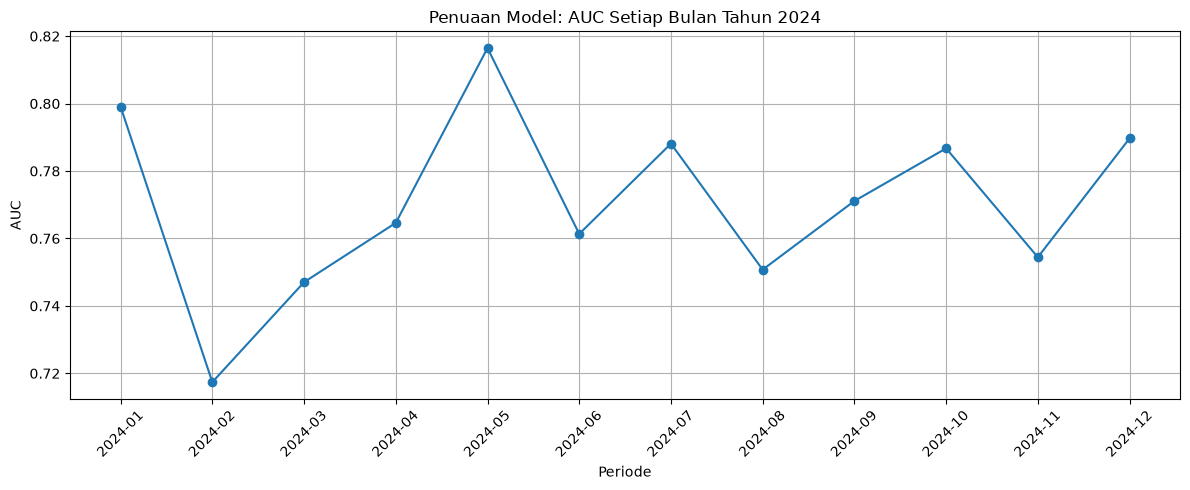

In [13]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(hasil["periode"], hasil["auc"], marker="o")

plt.title("Penuaan Model: AUC Setiap Bulan Tahun 2024")
plt.xlabel("Periode")
plt.ylabel("AUC")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


2.1 Memeriksa pergeseran komposisi populasi

In [14]:

# (a) Apakah komposisi populasi bergeser?
awal = df[df.periode <= "2022-06"]
akhir = df[df.periode >= "2024-07"]

print(pd.DataFrame({
    "awal": awal.segmen.value_counts(normalize=True),
    "akhir": akhir.segmen.value_counts(normalize=True)
}).round(3))


                   awal  akhir
segmen                        
pegawai_tetap     0.414  0.311
wiraswasta        0.251  0.232
pedagang_musiman  0.141  0.179
petani            0.129  0.167
nelayan           0.066  0.111


2.2 Memeriksa kinerja berdasarkan segmen

In [15]:

# (b) Apakah kinerja memburuk merata, atau terpusat pada segmen tertentu?
uji = df.periode > "2024-06"
skor = model.predict_proba(X[uji])[:, 1]

for seg, g in df[uji].groupby("segmen"):
    idx = g.index
    s = pd.Series(skor, index=df[uji].index)
    print(f"{seg:<18} n={len(g):5d} auc={roc_auc_score(y.loc[idx], s.loc[idx]):.3f}")


nelayan            n=  597 auc=0.792
pedagang_musiman   n=  965 auc=0.766
pegawai_tetap      n= 1680 auc=0.784
petani             n=  904 auc=0.708
wiraswasta         n= 1254 auc=0.772


Memperagakan Training–Serving Skew